In [94]:
%pip install ultralytics

import numpy as np
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import math
from time import time

model = YOLO("yolov8n-seg.pt")  # loading a pretrained model, in this case the YOLOV8 nano model
# img = cv2.imread("bus.jpg")

Note: you may need to restart the kernel to use updated packages.


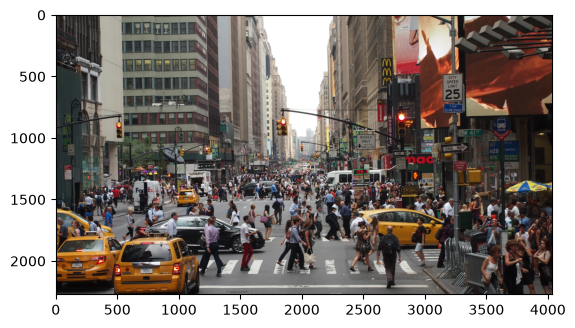

In [95]:
img = cv2.imread("./traffic_3.jpg")
imgBGR = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(imgBGR)

2272 4032
identifying objects...
done in 0.138s.
56 objects found


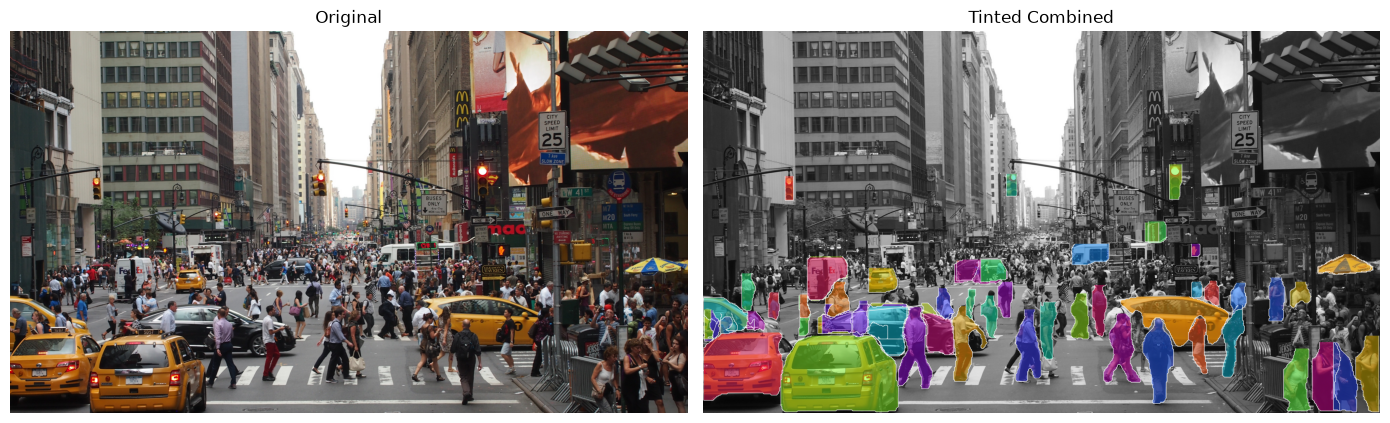

In [ ]:
assert img is not None, "file could not be read, check the path"
H, W = img.shape[:2]
# 3. Run inference (one image, so take the first result)
model_time = time()
print('identifying objects...')
result = model(img, conf=0.1, verbose=False)[0]
print(f"done in {time() - model_time:0.3f}s.")
# print(result.masks)

if result.masks is None:
    print("No objects detected")
else:
    print(len(result.masks.xy), "objects found")

    # INIT MASKS
    obj1_bg0_mask = np.zeros((H,W), np.uint8)
    object_color_layer_mask = np.zeros_like(img)
    # object_original_layer_mask = 

    outline1_bg0_mask = np.zeros((H,W), np.uint8)
    outline_color_layer_mask = np.zeros_like(img)
    outline_tinted_layer_mask = np.zeros_like(img)

    # CREATE BACKGROUND, B&W
    bw_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
    bw_img3 = cv2.cvtColor(bw_img, cv2.COLOR_GRAY2BGR) 
    bw_img3_2 = cv2.cvtColor(bw_img, cv2.COLOR_GRAY2BGR)

    # print(result)

    # reslt loop 
    for i, poly in enumerate(result.masks.xy):

        # YOLO result produces float coordinates, cv2 takes int
        polygon_points = poly.astype(np.int32)

        # COLOR LAYERS
        # draw white outline later of polygons
        cv2.polylines(outline_color_layer_mask, [polygon_points], True, (255, 255, 255), thickness=10) # BGR
        # create a color layer wintin polygon mask
        red   = math.sin(i + 0) * 127 + 128
        green = math.sin(i + 2) * 127 + 128
        blue  = math.sin(i + 4) * 127 + 128
        cv2.fillPoly(object_color_layer_mask, [polygon_points], (int(blue), int(green), int(red)))   # BGR ints

        

        # BOOLEAN MASK ASSIGNMENT
        # inside detected obj POLYS, set pixels to 1
        cv2.fillPoly(obj1_bg0_mask, [polygon_points], 1)
        # inside detected obj OUTLINES, set pixels to 1
        cv2.polylines(outline1_bg0_mask, [polygon_points], False, 1, 2)

    # convert bg fg mask to boolean arrays
    background0_foreground1_mask_boolean_array = np.where(obj1_bg0_mask == 1, True, False)
    background0_outline1_mask_boolean_array = np.where(outline1_bg0_mask == 1, True, False)
    

    # COMBINE LAYERS 
    # replace foreground of base image with color layer 
    bw_img3[background0_foreground1_mask_boolean_array] = object_color_layer_mask[background0_foreground1_mask_boolean_array]
    # composite outlines on top???
    bw_img3[background0_outline1_mask_boolean_array] = outline_color_layer_mask[background0_outline1_mask_boolean_array]

    # 

    # tinted layer
    # tinted_objects = cv2.addWeighted(img, 0.5, object_color_layer_mask, 0.5, 0)
    
    # original_color_objects = np.where(obj1_bg0_mask[..., None] == 1, img, 0)
    just_objects =  np.full_like(img, (0, 0, 0))
    just_objects[background0_foreground1_mask_boolean_array] = img.copy()[background0_foreground1_mask_boolean_array]
    tinted_objects = cv2.addWeighted(just_objects, 0.5, object_color_layer_mask, 0.5, 0)
    bw_img3_2[background0_foreground1_mask_boolean_array] = tinted_objects[background0_foreground1_mask_boolean_array]
    bw_img3_2[background0_outline1_mask_boolean_array] = outline_color_layer_mask[background0_outline1_mask_boolean_array]




    # tinted_combined

    # blended_objects = cv2.addWeighted(img.copy(), 0.5, object_color_layer_mask, 0.5, 0)

    


    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
    axes[1].imshow(cv2.cvtColor(bw_img3_2, cv2.COLOR_BGR2RGB)); axes[1].set_title("Tinted Combined")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()



Fitting model on a small sub-sample of the data
done in 0.193s.
Predicting color indices on the full image (k-means)
done in 0.132s.


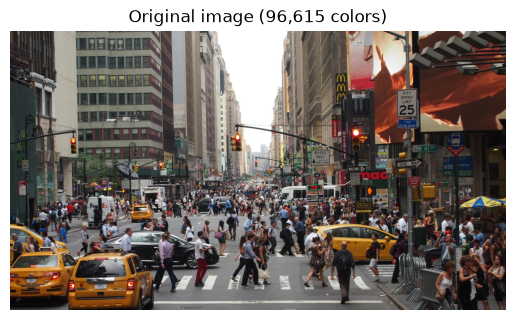

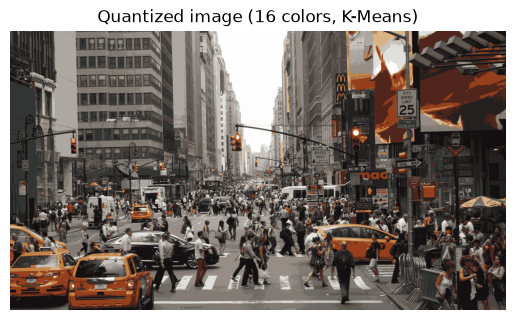

In [98]:
# k-means image 

# Authors: Robert Layton <robertlayton@gmail.com>
#          Olivier Grisel <olivier.grisel@ensta.org>
#          Mathieu Blondel <mathieu@mblondel.org>
#
# License: BSD 3 clause

# from time import time

# import matplotlib.pyplot as plt
# import numpy as np

from sklearn.cluster import KMeans
# from sklearn.datasets import load_sample_image
# from sklearn.metrics import pairwise_distances_argmin
from sklearn.utils import shuffle

n_colors = 16

# Load the Summer Palace photo
# k_img = load_sample_image("traffic_3.jpg")
# k_img = cv2.imread("./traffic_cam_screencap.png")
k_img = cv2.imread("./traffic_3.jpg")
# k_img = bw_img3_2
k_img_BGR = cv2.cvtColor(k_img, cv2.COLOR_BGR2RGB)
# Convert to floats instead of the default 8 bits integer coding. Dividing by
# 255 is important so that plt.imshow works well on float data (need to
# be in the range [0-1])
k_img_BGR_np = np.array(k_img_BGR, dtype=np.float64) / 255

# Load Image and transform to a 2D numpy array.
w, h, d = original_shape = tuple(k_img_BGR_np.shape)
assert d == 3
image_array = np.reshape(k_img_BGR_np, (w * h, d))

print("Fitting model on a small sub-sample of the data")
t0 = time()
image_array_sample = shuffle(image_array, random_state=0, n_samples=1_000)
kmeans = KMeans(n_clusters=n_colors, random_state=0).fit(image_array_sample)
print(f"done in {time() - t0:0.3f}s.")

# Get labels for all points
print("Predicting color indices on the full image (k-means)")
t0 = time()
labels = kmeans.predict(image_array)
print(f"done in {time() - t0:0.3f}s.")

def recreate_image(codebook, labels, w, h):
    """Recreate the (compressed) image from the code book & labels"""
    return codebook[labels].reshape(w, h, -1)


# Display all results, alongside original image
plt.figure(1)
plt.clf()
plt.axis("off")
plt.title("Original image (96,615 colors)")
plt.imshow(k_img_BGR)

plt.figure(2)
plt.clf()
plt.axis("off")
plt.title(f"Quantized image ({n_colors} colors, K-Means)")
plt.imshow(recreate_image(kmeans.cluster_centers_, labels, w, h))
